<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-16/lab-080b-rbm-ground-state.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 080b. Training a restricted Boltzmann machine towards the ground state of a spin chain

This notebook belongs to Lecture 16 and continues Lab 080 of Lecture 15. Lab 080 wrote the wave function of the open transverse-field Ising chain as a restricted Boltzmann machine (RBM), expressed the energy and every Pauli string as averages of local values over snapshots, and sampled the snapshots with the Metropolis algorithm. It sampled a network with twelve hidden units whose parameters it read from a file, and this notebook finds those parameters. No data set exists for this task. The network must find the ground state from the Hamiltonian alone, by lowering its energy. Lab 088 follows and evolves the same kind of network in imaginary and real time.

We take the chain with $N=12$ spins at the critical field $g=J$. We show that the energy of the network is bounded from below by the ground-state energy, train the network with exact sums over all $4096$ configurations, and then train it from sampled snapshots alone by variational Monte Carlo, whose gradient is a covariance of two quantities evaluated on every snapshot. The exact sums serve as a reference and as a check of every sampled quantity. The exact-sum training writes the file `data/rbm_tfim_N12_M12_params.npz` with the trained parameters and their starting values, and a copy of this file in the folder of Lecture 15 is the file that Lab 080 reads.

The core route consists of Sections 1 to 5 and took 38 seconds in the recorded run. It ends with the line "The core route ends here." Sections 6 to 8 are work for home and took 177 seconds. They scan the number of hidden units, treat the ordered phase at $g=0.5J$ and run a longer variational Monte Carlo training.

## 1. Libraries

NumPy and SciPy build the Hamiltonian as a sparse matrix and find its ground state. JAX evaluates the network for many configurations at once, computes gradients by automatic differentiation, runs the Metropolis chains and compiles the training steps. All calculations run in double precision on the CPU, and the GPU is never used. The optimiser Adam [3] comes from the Optax library [4], and Matplotlib draws the figures. Cells or parts of cells whose first comment reads "bookkeeping", "check" or "figure" save files, test a formula or draw plots, and they may be skipped on a first reading.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['rbm_tfim_N12_M12_params.npz']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-16/data/{name}", f"data/{name}")

In [1]:
# Bookkeeping cell (can be skipped on a first reading): imports, CPU-only JAX, thread limit, figure style and helpers.
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the GPU is never used; every array of this notebook is small
os.environ.setdefault("OMP_NUM_THREADS", "4")   # takes effect only if NumPy is not yet loaded (execute_classroom.py fixes one OpenBLAS thread)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=true intra_op_parallelism_threads=4")
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as sparse_linalg
import jax
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)       # double precision, needed for energy errors of order 1e-6
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
DATA = Path("data"); DATA.mkdir(exist_ok=True)     # the trained parameters, read by Lab 080 of Lecture 15
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
# one palette for the whole notebook: exact results black, RBM orange,
# RBM without biases teal, sampled quantities purple, auxiliary lines grey
COL = dict(exact="black", rbm="#D35A05", even="#1B9E77", sampled="#6A3D9A", grey="#9AA0A6")
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}

# --- bookkeeping (may be skipped): saving figures and numbers ---
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
def panels(name, draws):
    # notes: panels side by side at 7.0 x 2.9 in, 11 pt; slides: every panel also as its own file at 4.6 x 3.1 in
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax)
        ax.set_title(f"({lab})", loc="left", fontsize=11)
    fig.tight_layout(); save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(SLIDE_RC):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax)
            single.tight_layout(); save(single, f"{name}_{lab}"); plt.close(single)
def one_panel(name, draw):
    # a single-panel figure, one file at 4.6 x 3.1 in with 12.5 pt fonts (readable in the notes and on a slide)
    with plt.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(4.6, 3.1))
        draw(ax)
        fig.tight_layout(); save(fig, name); plt.show()
def sci(x, digits=1):
    # a number as LaTeX scientific notation, e.g. 2.1\times10^{-3}
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
started = time.perf_counter()
NUMBERS = {}                                    # every number quoted in the text, written to a macro file at the end
key = jax.random.PRNGKey(80)                    # initial parameters and Monte Carlo sampling, the same key as in Lab 080
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The chain, the network and the local energy

Lab 080 derived the formulas of this section, and we restate them so that this notebook can be read on its own. The transverse-field Ising chain [2] of $N$ spins has the Hamiltonian
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat\sigma^z_i\hat\sigma^z_{i+1}-g\sum_{i=0}^{N-1}\hat\sigma^x_i , \tag{1}$$
with $J=1$ as the unit of energy and an open chain of $N=12$ sites. A basis state is a bit string $\mathbf s=s_0s_1\dots s_{N-1}$ with $s_i\in\{0,1\}$, the spin of site $i$ is $\sigma_i=1-2s_i=\pm1$, the eigenvalue of $\hat\sigma^z_i$, and $\mathbf s^{(i)}$ is the bit string with bit $i$ flipped. The only nonzero matrix elements of $\hat{\mathcal H}$ are
$$\langle\mathbf s|\hat{\mathcal H}|\mathbf s\rangle=-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1},\qquad \langle\mathbf s^{(i)}|\hat{\mathcal H}|\mathbf s\rangle=-g ,\quad i=0,\dots,N-1 . \tag{2}$$
All off-diagonal elements are non-positive, so the ground state has positive amplitudes, and a network with real parameters suffices. The RBM with $M$ hidden units, visible biases $a_i$, hidden biases $b_j$ and weights $w_{ij}$ between spin $i$ and hidden unit $j$ gives, after the sum over the hidden units $h_j=\pm1$, the amplitude
$$\psi(\mathbf s)=\exp\Big(\sum_ia_i\sigma_i\Big)\prod_{j=1}^{M}2\cosh u_j(\mathbf s),\qquad u_j(\mathbf s)=b_j+\sum_iw_{ij}\sigma_i , \tag{3}$$
where $u_j$ is the input of hidden unit $j$. The parameters are collected in $\boldsymbol\theta=(a,b,w)$. In the code they are stored in a dictionary `p` with the keys `"a"`, `"b"` and `"W"`, and the array `p["W"]` of shape $(N,M)$ holds the weights $w_{ij}$. A measurement of all spins along $z$ returns the snapshot $\mathbf s$ with the Born probability
$$p(\mathbf s)=\frac{\psi(\mathbf s)^2}{Z},\qquad Z=\sum_{\mathbf s}\psi(\mathbf s)^2 . \tag{4}$$
The energy of the state of the network is the average of the local energy $E_{\rm loc}$ over the snapshots,
$$\mathcal E(\boldsymbol\theta)=\frac{\langle\psi_{\boldsymbol\theta}|\hat{\mathcal H}|\psi_{\boldsymbol\theta}\rangle}{\langle\psi_{\boldsymbol\theta}|\psi_{\boldsymbol\theta}\rangle}=\sum_{\mathbf s}p(\mathbf s)\,E_{\rm loc}(\mathbf s),\qquad E_{\rm loc}(\mathbf s)=\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\frac{\psi(\mathbf s')}{\psi(\mathbf s)}=-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1}-g\sum_{i=0}^{N-1}\frac{\psi(\mathbf s^{(i)})}{\psi(\mathbf s)} . \tag{5}$$
We write $\mathcal E$ for the energy of a quantum state and keep $E(\boldsymbol\sigma,\mathbf h)$ for the energy of the classical network. If the state is an eigenstate of $\hat{\mathcal H}$ with energy $\mathcal E$, every snapshot has $E_{\rm loc}(\mathbf s)=\mathcal E$, so the local energy does not fluctuate. This zero-variance property makes the local energy fluctuate less the closer the network comes to the ground state.

For two spins at $g=J$ the amplitudes $\psi(00)=\psi(11)=1$ and $\psi(01)=\psi(10)=\zeta$ give the local energies
$$E_{\rm loc}(00)=-J-2g\zeta,\qquad E_{\rm loc}(01)=J-\frac{2g}{\zeta} , \tag{6}$$
which agree, and both equal $-\sqrt5\,J$, at the ground state $\zeta=(\sqrt5-1)/2$. The code writes `r` for the ratio $\zeta$ and `r_star` for $(\sqrt5-1)/2$.

The snapshots come from the Metropolis algorithm [6]. A chain sits at a configuration $\mathbf s$, picks a random site $i$ and moves to $\mathbf s^{(i)}$ with the probability
$$A(\mathbf s\to\mathbf s^{(i)})=\min\Big(1,\frac{\psi(\mathbf s^{(i)})^2}{\psi(\mathbf s)^2}\Big) , \tag{7}$$
in which $Z$ cancels. A sweep consists of $N$ such proposals. The average of a function $O(\mathbf s)$ over $N_{\rm s}$ independent snapshots and its statistical error are
$$\bar O=\frac{1}{N_{\rm s}}\sum_{n=1}^{N_{\rm s}}O(\mathbf s_n),\qquad \Delta\bar O=\frac{s_O}{\sqrt{N_{\rm s}}} , \tag{8}$$
where $s_O$ is the standard deviation of $O$ over the snapshots.

We build the Hamiltonian (1), find its ground state with the Lanczos solver of SciPy [7], and define the amplitude (3), the energy (5) as an exact sum over all 4096 configurations, the local energy (5) on snapshots and the Metropolis walk (7). We check the energy at zero parameters, where all amplitudes are equal and the energy is $-gN$, and the two-spin ground state (6).

In [2]:
def bit_table(N):
    # row k holds the bits (s_0, ..., s_{N-1}) of basis state k; qubit 0 is the most significant bit, shape (2^N, N)
    return np.array(list(itertools.product([0, 1], repeat=N)))

def spins(bits):
    # sigma_i = 1 - 2 s_i, so bit 0 -> +1 and bit 1 -> -1 (the eigenvalue of sigma^z_i)
    return 1 - 2 * bits

N, J, g_c = 12, 1.0, 1.0                          # sites, coupling J (unit of energy), transverse field g = J
DIM = 2 ** N                                     # 4096 basis states

def flip_table(N):
    # FLIP[k, i] = index of bit string k with bit i flipped. Bit i carries the value 2^(N-1-i) in k,
    # so flipping it is the exclusive or (^) with that power of two. Shape (2^N, N).
    return np.arange(2 ** N)[:, None] ^ (1 << (N - 1 - np.arange(N)))[None, :]

def tfim_matrix(g, N, J=1.0):
    # equation (1) as a sparse 2^N x 2^N matrix with the matrix elements of equation (2):
    # diagonal  -J sum_i sigma_i sigma_{i+1};  -g between two bit strings that differ in exactly one bit
    sigma, flips = spins(bit_table(N)), flip_table(N)
    diagonal = -J * np.sum(sigma[:, :-1] * sigma[:, 1:], axis=1)           # shape (2^N,)
    rows = np.repeat(np.arange(2 ** N), N)                                 # row k repeated N times
    off_diagonal = sparse.csr_matrix((np.full(2 ** N * N, -g), (rows, flips.ravel())), shape=(2 ** N, 2 ** N))
    return (off_diagonal + sparse.diags(diagonal)).tocsr()

SIGMA = spins(bit_table(N))                      # all 4096 spin configurations, shape (4096, 12)
FLIP = flip_table(N)                             # shape (4096, 12)
DIAG = -J * np.sum(SIGMA[:, :-1] * SIGMA[:, 1:], axis=1)                    # diagonal of the matrix, shape (4096,)
S0SR = (SIGMA[:, :1] * SIGMA[:, 1:]).T           # row r-1 holds sigma_0 sigma_r of every configuration, shape (11, 4096)

def correlations(prob):
    # correlation C(r) = sum_s p(s) sigma_0 sigma_r for r = 1, ..., N-1; prob has shape (4096,)
    return S0SR @ prob

def exact_ground_state(g):
    # the two lowest eigenvalues of the sparse matrix by the Lanczos method of SciPy (eigsh)
    H = tfim_matrix(g, N)
    w, v = sparse_linalg.eigsh(H, k=2, which="SA")
    order = np.argsort(w); w, v = w[order], v[:, order]
    psi0 = v[:, 0] * np.sign(v[0, 0])            # overall sign fixed so that the first amplitude is positive
    return dict(H=H, E0=float(w[0]), gap=float(w[1] - w[0]), psi0=psi0, C=correlations(psi0 ** 2))

EXACT = {g_c: exact_ground_state(g_c)}
ex = EXACT[g_c]
print(f"N = {N}, g = J: ground-state energy E_0 = {ex['E0']:.6f} J, gap to the first excited state {ex['gap']:.4f} J")

# two spins at g = J, equation (6); r is the ratio zeta
H2 = tfim_matrix(g_c, 2).toarray()                           # the 4 x 4 matrix of the two-spin chain
E0_two = float(np.linalg.eigvalsh(H2)[0])
r_star = (np.sqrt(5) - 1) / 2                                # the ratio zeta of the ground state
e00 = lambda r: -J - 2 * g_c * r                             # equation (6)
e01 = lambda r: J - 2 * g_c / r
assert abs(E0_two + np.sqrt(5)) < 1e-12 and abs(e00(r_star) - e01(r_star)) < 1e-12
print(f"two spins: lowest eigenvalue {E0_two:.6f} J, E_loc(00) = E_loc(01) = {e00(r_star):.6f} J at zeta = {r_star:.6f}")

S = jnp.asarray(SIGMA, dtype=jnp.float64)        # all spin configurations, shape (4096, 12)
FLIP_J, DIAG_J = jnp.asarray(FLIP), jnp.asarray(DIAG)

def log_amplitude(p, sigma):
    # logarithm of equation (3) for real parameters p = dict(a, b, W), p["W"] holds the weights w_ij; sigma shape (n, N), result shape (n,)
    # ln(2 cosh u) = logaddexp(u, -u) is evaluated without overflow even for large |u|
    u = p["b"] + sigma @ p["W"]                              # shape (n, M)
    return sigma @ p["a"] + jnp.sum(jnp.logaddexp(u, -u), axis=-1)

def local_energies(p, g):
    # local energy (5) for all 4096 configurations at once. ln_psi[FLIP] has shape (4096, 12):
    # entry (k, i) is ln psi of configuration k with spin i flipped, so the ratio is exp(difference)
    ln_psi = log_amplitude(p, S)                             # shape (4096,)
    ratios = jnp.exp(ln_psi[FLIP_J] - ln_psi[:, None])       # psi(s^(i)) / psi(s), shape (4096, 12)
    return DIAG_J - g * jnp.sum(ratios, axis=1), ln_psi

def energy(p, g):
    # energy (5) as an exact sum: E(theta) = sum_s p(s) E_loc(s) with p(s) = psi(s)^2 / Z
    e_loc, ln_psi = local_energies(p, g)
    w = jnp.exp(2 * (ln_psi - jnp.max(ln_psi)))              # psi^2 up to a constant factor, no overflow
    return jnp.sum(w * e_loc) / jnp.sum(w)

def rbm_state(p):
    # the 4096 amplitudes of equation (3), normalised to one
    ln_psi = log_amplitude(p, S)
    psi = jnp.exp(ln_psi - jnp.max(ln_psi))
    return psi / jnp.linalg.norm(psi)

def init_params(rng_key, M, width=0.05):
    # small random real parameters: a shape (N,), b shape (M,), weights W shape (N, M)
    k_a, k_b, k_W = jax.random.split(rng_key, 3)
    return dict(a=width * jax.random.normal(k_a, (N,)), b=width * jax.random.normal(k_b, (M,)),
                W=width * jax.random.normal(k_W, (N, M)))

# check: all parameters zero give psi(s) = 2^M for every s, so E_loc(s) = DIAG(s) - g N and the energy is -g N
p_zero = dict(a=jnp.zeros(N), b=jnp.zeros(3), W=jnp.zeros((N, 3)))
E_zero = float(energy(p_zero, g_c))
assert abs(E_zero + g_c * N) < 1e-12
print(f"all parameters zero (equal amplitudes): energy {E_zero:.6f} J = -g N")

FLIP_ONE = jnp.asarray(1 - 2 * np.eye(N))                              # row i multiplies spin i by -1, shape (N, N)

def metropolis_sweeps(p, sigma, rng_key, sweeps):
    # Metropolis rule (7) on the visible spins only; n chains run side by side, sigma (n, N) holds their configurations.
    # One proposal: every chain picks a random site i and proposes s -> s^(i). It is accepted when ln u < 2 (ln psi(s') - ln psi(s))
    # with u uniform in (0, 1), which is min(1, psi(s')^2 / psi(s)^2) of equation (7). Z and the hidden units never appear.
    # One sweep = N proposals. Returns the configurations after every sweep, shape (sweeps, n, N), and the acceptance rate.
    n = sigma.shape[0]
    def proposal(carry, k):
        sigma, ln_psi = carry
        k_site, k_acc = jax.random.split(k)
        site = jax.random.randint(k_site, (n,), 0, N)                    # one random site per chain, shape (n,)
        sigma_new = sigma * (1 - 2 * jax.nn.one_hot(site, N))            # flip that spin, shape (n, N)
        ln_new = log_amplitude(p, sigma_new)
        accept = jnp.log(jax.random.uniform(k_acc, (n,))) < 2 * (ln_new - ln_psi)
        return (jnp.where(accept[:, None], sigma_new, sigma), jnp.where(accept, ln_new, ln_psi)), accept
    # jax.lax.scan(f, carry, keys) calls f once per key inside the compiled code and passes carry = (sigma, ln_psi) on
    def sweep(carry, k):
        carry, accepted = jax.lax.scan(proposal, carry, jax.random.split(k, N))
        return carry, (carry[0], jnp.mean(accepted))
    _, (history, acc) = jax.lax.scan(sweep, (sigma, log_amplitude(p, sigma)), jax.random.split(rng_key, sweeps))
    return history, jnp.mean(acc)
sample_sweeps = jax.jit(metropolis_sweeps, static_argnums=3)

rng_mc = np.random.default_rng(8080)                                   # starting configurations of the chains, the generator of Lab 080
for _ in range(2):                                                     # Lab 080 drew the starting configurations of its two sampling
    rng_mc.integers(0, 2, (100, N))                                    # runs (100 chains each) first; skipping them reproduces the recorded run
random_spins = lambda n: jnp.asarray(1 - 2 * rng_mc.integers(0, 2, (n, N)), dtype=jnp.float64)   # random starting configurations
k_vmc, k_long = jax.random.split(jax.random.fold_in(key, 1000), 4)[2:]  # the split of Lab 080, whose sampling used the first two keys

def local_energy_parts(p, sigma, g):
    # local energy (5) on snapshots sigma (n, N): coupling part -J sum sigma_i sigma_{i+1} and field part -g sum_i psi(s^(i))/psi(s)
    ln_psi = log_amplitude(p, sigma)                                     # shape (n,)
    # sigma[:, None, :] * FLIP_ONE[None] has shape (n, N, N): copy i of snapshot n has spin i flipped
    ln_flipped = log_amplitude(p, (sigma[:, None, :] * FLIP_ONE[None]).reshape(-1, N)).reshape(-1, N)   # ln psi(s^(i)), shape (n, N)
    e_zz = -J * jnp.sum(sigma[:, :-1] * sigma[:, 1:], axis=-1)
    e_x = -g * jnp.sum(jnp.exp(ln_flipped - ln_psi[:, None]), axis=-1)
    return e_zz, e_x
MAG = SIGMA.sum(axis=1)                                                # total spin m = sum_i sigma_i of every configuration


N = 12, g = J: ground-state energy E_0 = -14.925971 J, gap to the first excited state 0.2512 J
two spins: lowest eigenvalue -2.236068 J, E_loc(00) = E_loc(01) = -2.236068 J at zeta = 0.618034
all parameters zero (equal amplitudes): energy -12.000000 J = -g N


## 3. Energy as the loss function

The classical RBM was trained on a fixed data set, and its loss measured how well the model distribution described those data. For the ground state no data set exists. The only input is the Hamiltonian (1). The configurations used below are generated by the network itself, sampled from $p(\mathbf s)=\psi(\mathbf s)^2/Z$ at the current parameters, and they change after every update of the parameters.

The loss is the energy (5) of the state of the network. The variational principle guarantees that this loss is bounded from below by the ground-state energy. Expanding the state $|\psi_{\boldsymbol\theta}\rangle=\sum_{\mathbf s}\psi(\mathbf s)|\mathbf s\rangle$ in the eigenstates $|n\rangle$ of $\hat{\mathcal H}$, with energies $\mathcal E_0\le\mathcal E_1\le\dots$ and coefficients $c_n=\langle n|\psi_{\boldsymbol\theta}\rangle$, gives
$$\mathcal E(\boldsymbol\theta)=\frac{\sum_n|c_n|^2\,\mathcal E_n}{\sum_n|c_n|^2}\;\ge\;\frac{\sum_n|c_n|^2\,\mathcal E_0}{\sum_n|c_n|^2}=\mathcal E_0 , \tag{9}$$
because every $\mathcal E_n$ is at least $\mathcal E_0$. Equality holds only when the state lies in the ground state. Minimising $\mathcal E(\boldsymbol\theta)$ over the parameters therefore drives the network towards the ground state, as far as the ansatz allows. The exact diagonalisation of Section 2 is possible for $N=12$ only, and it serves as a check of the result.

The normalisation makes the loss hard to evaluate for long chains, because $Z$ in equation (4) and the numerator of equation (5) are sums over all $2^N$ configurations. For fifty spins one double-precision number per configuration needs about $9\times10^{15}$ bytes, as Lab 080 showed, so a method for long chains must replace these sums by averages over sampled snapshots. For twelve spins the sums take milliseconds, and Section 4 uses them for a reference training.

## 4. Reference training with exact sums

With twelve sites the energy (5) can be minimised directly as an exact sum. The result is a trained network whose exact properties we know, the reference for the Monte Carlo training of Section 5 and the network that Lab 080 samples. We choose $M=12$ hidden units, as many as there are sites, which gives $12+12+144=168$ real parameters for 4096 amplitudes. The parameters start from small random numbers with standard deviation $0.05$. JAX computes the gradient of the exact-sum energy by automatic differentiation, and the Adam optimiser [3] of the Optax library [4] updates the parameters for 2000 iterations, with a step size that decreases along a cosine from $0.03$ to $3\times10^{-4}$. Four independent starts run in parallel. We follow two measures of quality,
$$\delta\mathcal E=\frac{\mathcal E(\boldsymbol\theta)-\mathcal E_0}{|\mathcal E_0|},\qquad F=\frac{|\langle\psi_0|\psi_{\boldsymbol\theta}\rangle|^2}{\langle\psi_{\boldsymbol\theta}|\psi_{\boldsymbol\theta}\rangle} , \tag{10}$$
the relative energy error and the fidelity with the exact normalised ground state $|\psi_0\rangle$, and we report the infidelity $1-F$. Both use the exact solution and serve only as diagnostics. The optimiser sees the energy alone.

g = J, M = 12: 168 real parameters, 4 starts, 2000 Adam steps, 8.7 s
exact ground-state energy E_0 = -14.925971 J
  start 0: E = -14.925641 J, relative error 2.2e-05, infidelity 4.1e-05
  start 1: E = -14.925638 J, relative error 2.2e-05, infidelity 4.1e-05
  start 2: E = -14.925743 J, relative error 1.5e-05, infidelity 2.6e-05
  start 3: E = -14.925766 J, relative error 1.4e-05, infidelity 2.6e-05
start 3 has the lowest energy; ratio of its amplitudes to the exact ones between 0.9658 and 1.0291, largest deviation of C(r) 5.0e-04


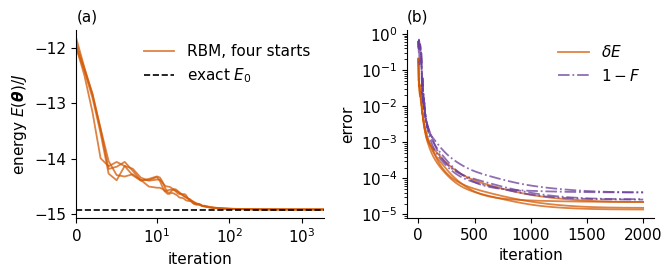

In [3]:
STEPS, LR, LR_END, STARTS = 2000, 0.03, 3e-4, 4
schedule = optax.cosine_decay_schedule(LR, STEPS, alpha=LR_END / LR)    # step size from 0.03 down to 3e-4
optimiser = optax.adam(schedule)                                        # Adam [3] from the Optax library [4]

def adam_run(p0, g, psi0):
    # one training run: gradient of the exact-sum energy (5) by automatic differentiation, then one Adam update.
    # jax.lax.scan repeats the step STEPS times and records E and F before every update.
    def step(carry, _):
        p, opt_state = carry
        E, grad = jax.value_and_grad(energy)(p, g)
        F = (rbm_state(p) @ psi0) ** 2                                  # fidelity (10), diagnostic only
        updates, opt_state = optimiser.update(grad, opt_state)
        return (optax.apply_updates(p, updates), opt_state), (E, F)
    (p, _), (E_hist, F_hist) = jax.lax.scan(step, (p0, optimiser.init(p0)), None, length=STEPS)
    return p, E_hist, F_hist

train_starts = jax.jit(jax.vmap(adam_run, in_axes=(0, None, None)))     # vmap: all starts at once

RUNS = {}
def run(g, M, use_biases=True):
    # STARTS independent trainings with M hidden units; every final state is compared with exact diagonalisation
    ref = EXACT[g]
    p_start = jax.vmap(lambda k: init_params(k, M))(jax.random.split(jax.random.fold_in(key, M), STARTS))
    if not use_biases:                                                  # Section 7: a = 0 and b = 0 throughout
        p_start = dict(a=jnp.zeros_like(p_start["a"]), b=jnp.zeros_like(p_start["b"]), W=p_start["W"])
    t0 = time.perf_counter()
    if use_biases:
        p, E_hist, F_hist = train_starts(p_start, g, jnp.asarray(ref["psi0"]))
    else:
        p, E_hist, F_hist = train_even(p_start, g, jnp.asarray(ref["psi0"]))
    # vmap stacked the starts along axis 0 of every array; one(tree, r) picks start r from each array of the dict
    # (train_even, used only with use_biases=False, is defined in Section 7)
    one = lambda tree, r: jax.tree_util.tree_map(lambda x: x[r], tree)
    psi = np.array([np.asarray(rbm_state(one(p, r))) for r in range(STARTS)])     # shape (STARTS, 4096)
    E = np.array([float(x @ (ref["H"] @ x)) for x in psi])
    E_hist = np.asarray(E_hist)
    out = dict(start=[one(p_start, r) for r in range(STARTS)], params=[one(p, r) for r in range(STARTS)], psi=psi, E=E,
               rel_err=(E - ref["E0"]) / abs(ref["E0"]), F=(psi @ ref["psi0"]) ** 2,
               C=np.array([correlations(x ** 2) for x in psi]), E_hist=E_hist, F_hist=np.asarray(F_hist),
               drift=(E_hist[:, -100] - E) / abs(ref["E0"]), seconds=time.perf_counter() - t0,
               n_params=N * M + (N + M if use_biases else 0))
    out["best"] = int(np.argmin(E))                                     # the start with the lowest final energy
    RUNS[g, M, use_biases] = out
    return out

M_MAIN = 12
r_main = run(g_c, M_MAIN)
print(f"g = J, M = {M_MAIN}: {r_main['n_params']} real parameters, {STARTS} starts, {STEPS} Adam steps, {r_main['seconds']:.1f} s")
print(f"exact ground-state energy E_0 = {ex['E0']:.6f} J")
for r in range(STARTS):
    print(f"  start {r}: E = {r_main['E'][r]:.6f} J, relative error {r_main['rel_err'][r]:.1e}, infidelity {1 - r_main['F'][r]:.1e}")
assert np.all(r_main["rel_err"] > -1e-12)                               # variational principle (9): no start below E_0
b_main = r_main["best"]
psi_rbm = r_main["psi"][b_main]                                         # normalised amplitudes of the best start, shape (4096,)
p_init = r_main["start"][b_main]                                        # the best start before training, the start of Section 5
# bookkeeping (may be skipped): the trained parameters and their starting values, read by Lab 080 of Lecture 15
np.savez(DATA / "rbm_tfim_N12_M12_params.npz", **{k_: np.asarray(r_main["params"][b_main][k_]) for k_ in ("a", "b", "W")},
         **{k_ + "_init": np.asarray(p_init[k_]) for k_ in ("a", "b", "W")}, g=g_c, N=N, E0=ex["E0"])
amp_ratio = psi_rbm / ex["psi0"]
corr_err_main = float(np.max(np.abs(r_main["C"][b_main] - ex["C"])))
print(f"start {b_main} has the lowest energy; ratio of its amplitudes to the exact ones between {amp_ratio.min():.4f} and {amp_ratio.max():.4f},"
      f" largest deviation of C(r) {corr_err_main:.1e}")

# --- figure (drawing code may be skipped) ---
steps_axis = np.arange(STEPS)
def draw_train_a(ax):
    for r in range(STARTS):
        ax.plot(steps_axis, r_main["E_hist"][r], color=COL["rbm"], lw=1.3, alpha=0.75, label="RBM, four starts" if r == 0 else None)
    ax.axhline(ex["E0"], color=COL["exact"], ls="--", lw=1.2, label=r"exact $E_0$")
    ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, STEPS)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"energy $E(\boldsymbol{\theta})/J$"); ax.legend(frameon=False)
def draw_train_b(ax):
    for r in range(STARTS):
        ax.semilogy(steps_axis, (r_main["E_hist"][r] - ex["E0"]) / abs(ex["E0"]), color=COL["rbm"], lw=1.3, alpha=0.75,
                    label=r"$\delta E$" if r == 0 else None)
        ax.semilogy(steps_axis, 1 - r_main["F_hist"][r], color=COL["sampled"], lw=1.3, alpha=0.75, ls="-.",
                    label="$1-F$" if r == 0 else None)
    ax.set_xlabel("iteration"); ax.set_ylabel("error"); ax.legend(frameon=False)
panels("fig_lab080_energy_training", [draw_train_a, draw_train_b])
NUMBERS.update(Steps=str(STEPS), Starts=str(STARTS),
               RelErrMain=sci(r_main["rel_err"][b_main]), InfidelityMain=sci(1 - r_main["F"][b_main]),
               RelErrMainWorst=sci(r_main["rel_err"].max()), InfidelityMainWorst=sci(1 - r_main["F"].min()),
               RelErrMainBest=sci(r_main["rel_err"].min()), InfidelityMainBest=sci(1 - r_main["F"].max()),
               CorrErrMain=sci(corr_err_main), AmpRatioMin=f"{amp_ratio.min():.3f}", AmpRatioMax=f"{amp_ratio.max():.3f}")

Panel (a) shows the energy of the four starts against the iteration, with a horizontal axis that is linear up to ten iterations and logarithmic beyond, and $\mathcal E_0$ as the dashed line. All starts begin near $-12\,J$, the energy of equal amplitudes, and approach the line within about one hundred iterations. Panel (b) shows the relative energy error and the infidelity on a logarithmic axis. After 2000 iterations the best start has $\delta\mathcal E=1.4\times10^{-5}$ and $1-F=2.6\times10^{-5}$, no start lies below $\mathcal E_0$, and the amplitudes of the best start differ from the exact ones by a few percent at most. The cell wrote this best start and its initial parameters to `data/rbm_tfim_N12_M12_params.npz`. Lab 080 reads this file and samples the trained network, and Section 5 starts the Monte Carlo training from the same initial parameters. The figure labels write $\delta E$ for $\delta\mathcal E$.

## 5. Training by variational Monte Carlo

Section 4 minimised the energy with exact sums, which Section 3 showed to be impossible for long chains. The gradient of the energy is also an average over the snapshots, and estimating it from samples gives the method called variational Monte Carlo [5]. The derivative of the amplitude enters through the quantity
$$O_k(\mathbf s)=\frac{\partial\ln\psi(\mathbf s)}{\partial\theta_k}=\frac{1}{\psi(\mathbf s)}\frac{\partial\psi(\mathbf s)}{\partial\theta_k} , \tag{11}$$
which says by what fraction a small increase of the parameter $\theta_k$ raises the amplitude of configuration $\mathbf s$. Configurations with a large $O_k$ gain weight when $\theta_k$ grows, and configurations with a small or negative $O_k$ lose weight.

We differentiate the energy (5), written with the real symmetric matrix elements $H_{\mathbf s\mathbf s'}=\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle$ and $Z=\sum_{\mathbf s}\psi(\mathbf s)^2$. The quotient rule gives one term from the numerator and one from $Z$,
$$\frac{\partial\mathcal E}{\partial\theta_k}=\frac{1}{Z}\sum_{\mathbf s,\mathbf s'}\Big[\frac{\partial\psi(\mathbf s)}{\partial\theta_k}H_{\mathbf s\mathbf s'}\psi(\mathbf s')+\psi(\mathbf s)H_{\mathbf s\mathbf s'}\frac{\partial\psi(\mathbf s')}{\partial\theta_k}\Big]-\frac{\sum_{\mathbf s,\mathbf s'}\psi(\mathbf s)H_{\mathbf s\mathbf s'}\psi(\mathbf s')}{Z^2}\sum_{\mathbf s}2\psi(\mathbf s)\frac{\partial\psi(\mathbf s)}{\partial\theta_k} . \tag{12}$$
Because $H_{\mathbf s\mathbf s'}=H_{\mathbf s'\mathbf s}$, exchanging the summation labels in the second term of the bracket turns it into the first, so the bracket equals twice its first term. Writing $\partial\psi(\mathbf s)/\partial\theta_k=\psi(\mathbf s)O_k(\mathbf s)$ and the second fraction as $\mathcal E/Z$ gives
$$\frac{\partial\mathcal E}{\partial\theta_k}=2\sum_{\mathbf s}\underbrace{\frac{\psi(\mathbf s)^2}{Z}}_{p(\mathbf s)}O_k(\mathbf s)\underbrace{\sum_{\mathbf s'}H_{\mathbf s\mathbf s'}\frac{\psi(\mathbf s')}{\psi(\mathbf s)}}_{E_{\rm loc}(\mathbf s)}-2\,\mathcal E\sum_{\mathbf s}p(\mathbf s)O_k(\mathbf s)
=2\Big(\langle E_{\rm loc}O_k\rangle-\langle E_{\rm loc}\rangle\langle O_k\rangle\Big) , \tag{13}$$
where $\langle\cdot\rangle$ is the average over $p(\mathbf s)$ and $\mathcal E=\langle E_{\rm loc}\rangle$ by equation (5). The gradient is twice the covariance of the local energy and $O_k$ over the snapshots of the current state. We write it $\partial_k\mathcal E=\partial\mathcal E/\partial\theta_k$ for short. With $N_{\rm s}$ snapshots it is estimated by
$$\partial_k\mathcal E\approx\frac{2}{N_{\rm s}}\sum_{n=1}^{N_{\rm s}}\big(E_{\rm loc}(\mathbf s_n)-\bar{\mathcal E}\big)\,O_k(\mathbf s_n),\qquad \bar{\mathcal E}=\frac{1}{N_{\rm s}}\sum_{n=1}^{N_{\rm s}}E_{\rm loc}(\mathbf s_n) . \tag{14}$$

The covariance has a direct reading. If the configurations that $\theta_k$ favours, those with a large $O_k$, have a local energy above the average, the covariance is positive and gradient descent lowers $\theta_k$. Amplitude then moves from configurations that cost energy to configurations that save it. At an exact eigenstate the local energy is the same for every snapshot, by the zero-variance property of Section 2, so every covariance vanishes and the training stops. Away from an eigenstate the sampled gradient carries statistical noise, which shrinks together with the spread of the local energy.

Two spins again show the mechanism with one parameter. We take $\psi(00)=\psi(11)=1$ and $\psi(01)=\psi(10)=e^{\theta}$, so that $\zeta=e^\theta$ is the ratio of equation (6). Then $O=0$ on the two aligned configurations and $O=1$ on the two antiparallel ones. With $q$ the total probability of the antiparallel configurations, $\langle O\rangle=q$, $\langle E_{\rm loc}O\rangle=q\,E_{\rm loc}(01)$ and $\langle E_{\rm loc}\rangle=(1-q)E_{\rm loc}(00)+q\,E_{\rm loc}(01)$, and equation (13) becomes
$$\frac{d\mathcal E}{d\theta}=2q(1-q)\big[E_{\rm loc}(01)-E_{\rm loc}(00)\big],\qquad q=\frac{2e^{2\theta}}{2+2e^{2\theta}} . \tag{15}$$
The gradient is positive when the antiparallel configurations have the higher local energy, so descent lowers their amplitude, and it vanishes where the two local energies of equation (6) are equal, at $\zeta=(\sqrt5-1)/2$. We run plain gradient descent, $\theta\leftarrow\theta-\eta\,d\mathcal E/d\theta$ with $\eta=0.1$, from $\theta=0$, once with the exact gradient (15) and once with the estimate (14) from 200 snapshots per iteration. With four configurations the snapshots are drawn directly from the four probabilities, without a Markov chain.

theta = 0: q = 0.50, E_loc(00) = -3 J, E_loc(01) = -1 J, gradient (15) = 1.00
exact    gradient: final zeta = 0.6180, final energy -2.2361 J, last gradient +1.1e-07
sampled  gradient: final zeta = 0.6180, final energy -2.2361 J, last gradient +1.2e-07
target: zeta = 0.6180, E = -sqrt5 J = -2.2361 J


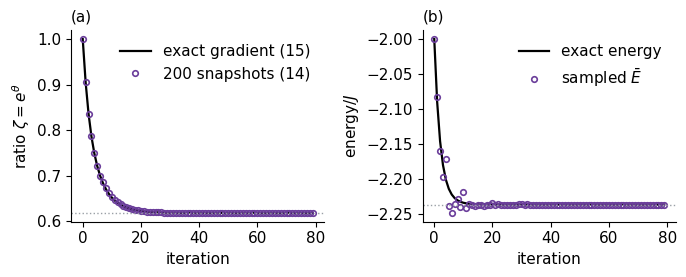

In [4]:
eta, DESCENT_STEPS, N_SNAP_TWO = 0.1, 80, 200
two_configs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
def two_spin_quantities(theta):
    # amplitudes (1, e^theta, e^theta, 1), Born probabilities, local energies (6) and O = d ln psi / d theta
    r = np.exp(theta)
    psi = np.array([1.0, r, r, 1.0])
    e_loc = np.array([e00(r), e01(r), e01(r), e00(r)])
    O = np.array([0.0, 1.0, 1.0, 0.0])
    return psi ** 2 / np.sum(psi ** 2), e_loc, O

rng_two = np.random.default_rng(802)
DESCENT = {"exact": [], "sampled": []}
for kind in DESCENT:
    theta = 0.0
    for t in range(DESCENT_STEPS):
        prob, e_loc, O = two_spin_quantities(theta)
        if kind == "exact":
            grad = 2 * (prob @ (e_loc * O) - (prob @ e_loc) * (prob @ O))      # equation (13), exact averages
            E_now = prob @ e_loc
        else:
            n = rng_two.choice(4, size=N_SNAP_TWO, p=prob)                    # 200 snapshots drawn from p(s)
            E_now = e_loc[n].mean()
            grad = 2 * np.mean((e_loc[n] - E_now) * O[n])                     # equation (14)
        DESCENT[kind].append((theta, E_now, grad))
        theta -= eta * grad                                                   # plain gradient descent
    DESCENT[kind] = np.array(DESCENT[kind])
q0 = two_spin_quantities(0.0)[0][1] * 2
print(f"theta = 0: q = {q0:.2f}, E_loc(00) = {e00(1.0):.0f} J, E_loc(01) = {e01(1.0):.0f} J, gradient (15) = {2 * q0 * (1 - q0) * (e01(1.0) - e00(1.0)):.2f}")
for kind, d in DESCENT.items():
    print(f"{kind:8s} gradient: final zeta = {np.exp(d[-1, 0]):.4f}, final energy {d[-1, 1]:.4f} J, last gradient {d[-1, 2]:+.1e}")
print(f"target: zeta = {r_star:.4f}, E = -sqrt5 J = {-np.sqrt(5):.4f} J")
assert abs(np.exp(DESCENT["exact"][-1, 0]) - r_star) < 1e-6

# --- figure (drawing code may be skipped) ---
def draw_desc_a(ax):
    ax.plot(np.exp(DESCENT["exact"][:, 0]), color=COL["exact"], lw=1.6, label="exact gradient (15)")
    ax.plot(np.exp(DESCENT["sampled"][:, 0]), "o", color=COL["sampled"], ms=4, mfc="none", mew=1.2, label="200 snapshots (14)")
    ax.axhline(r_star, color=COL["grey"], ls=":", lw=1.0)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"ratio $\zeta=e^{\theta}$"); ax.legend(frameon=False)
def draw_desc_b(ax):
    ax.plot(DESCENT["exact"][:, 1], color=COL["exact"], lw=1.6, label="exact energy")
    ax.plot(DESCENT["sampled"][:, 1], "o", color=COL["sampled"], ms=4, mfc="none", mew=1.2, label=r"sampled $\bar E$")
    ax.axhline(-np.sqrt(5), color=COL["grey"], ls=":", lw=1.0)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"energy$/J$"); ax.legend(frameon=False)
panels("fig_lab080_two_spin_descent", [draw_desc_a, draw_desc_b])

Panel (a) shows the ratio $\zeta$ and panel (b) the energy against the iteration, with dotted lines at $\zeta=(\sqrt5-1)/2$ and $\mathcal E=-\sqrt5\,J$. Both runs reach the eigenstate. The sampled run scatters on the way but stops at the target, because at $\zeta=(\sqrt5-1)/2$ every snapshot has the local energy $-\sqrt5\,J$, and then the sampled covariance (14) is zero for any set of snapshots. Away from the eigenstate the snapshots also spread the energy estimate, and at the eigenstate this spread disappears as well.

For the RBM the logarithm of the amplitude (3) is $\ln\psi=\sum_ia_i\sigma_i+\sum_j\ln 2\cosh u_j$, and $d\ln(2\cosh u)/du=\tanh u$. The derivatives (11) are therefore
$$O_{a_i}(\mathbf s)=\sigma_i,\qquad O_{b_j}(\mathbf s)=\tanh u_j(\mathbf s),\qquad O_{w_{ij}}(\mathbf s)=\sigma_i\tanh u_j(\mathbf s) , \tag{16}$$
with the hidden input $u_j(\mathbf s)=b_j+\sum_iw_{ij}\sigma_i$ of equation (3). The quantity $\tanh u_j$ is the average value of the hidden unit $h_j=\pm1$ for the fixed spins $\boldsymbol\sigma$, the same conditional average that block Gibbs sampling used in the classical RBM. We implement equations (14) and (16) and check them, with the exact probabilities in place of the sample average, against the automatic derivative of the exact-sum energy of Section 2.

In [5]:
def log_derivatives(p, sigma):
    # equation (16): O_k(s) = d ln psi(s) / d theta_k for every parameter; sigma shape (n, N)
    t = jnp.tanh(p["b"] + sigma @ p["W"])                               # tanh u_j(s), shape (n, M)
    return dict(a=sigma, b=t, W=sigma[:, :, None] * t[:, None, :])      # shapes (n, N), (n, M), (n, N, M)

def covariance_gradient(p, sigma, e_loc, weights):
    # equation (13): 2 (<E_loc O_k> - <E_loc><O_k>) with the average <x> = sum_n weights_n x_n.
    # weights = 1/N_s for snapshots gives the estimate (14); weights = p(s) on all 4096 configurations gives the exact gradient
    O = log_derivatives(p, sigma)                                       # dict of arrays with the snapshot index n first
    # tensordot(w, o, axes=1) sums over n: sum_n w_n O_k(s_n) for every parameter k, keeping the shape of that parameter
    e_mean = weights @ e_loc
    return jax.tree_util.tree_map(
        lambda o: 2 * (jnp.tensordot(weights * e_loc, o, axes=1) - e_mean * jnp.tensordot(weights, o, axes=1)), O)

# check (may be skipped): the exact covariance gradient against automatic differentiation of the exact energy (5)
e_all, ln_all = local_energies(p_init, g_c)
p_all = jnp.exp(2 * (ln_all - ln_all.max())); p_all = p_all / p_all.sum()           # exact Born probabilities, shape (4096,)
g_cov = covariance_gradient(p_init, S, e_all, p_all)
g_auto = jax.grad(energy)(p_init, g_c)
grad_check = max(float(jnp.max(jnp.abs(g_cov[k_] - g_auto[k_])) / jnp.max(jnp.abs(g_auto[k_]))) for k_ in g_auto)
print(f"largest relative difference between equation (13) and automatic differentiation: {grad_check:.1e}")
assert grad_check < 1e-10

largest relative difference between equation (13) and automatic differentiation: 5.2e-14


The two gradients agree to numerical precision. The classical RBM was trained with a rule of the same structure. Maximising the log-likelihood of data gave the Boltzmann learning rule for the weights $W_{ij}$ between the units with the values 0 and 1 of Lecture 14,
$$\frac{\partial\,\overline{\ln P(\mathbf v)}}{\partial W_{ij}}=\langle v_ih_j\rangle_{\rm data}-\langle v_ih_j\rangle_{\rm model} , \tag{17}$$
where the bar averages over the training data, the first average takes the visible units from the data and the hidden units from their conditional distribution, and the second average is over the model distribution. Equations (13) and (17) are both an average minus an average. Contrastive divergence approximates the model average of (17) by a few block Gibbs steps started from the data, so it needs a data set. A data set exists when snapshots measured on a prepared quantum state train the network by this rule, which reconstructs that state and is called neural-network quantum state tomography [9]. A ground state has no data. Both averages of equation (13) are taken over snapshots that the network generates itself, and the Hamiltonian enters only through the local energy. The gradient (13) can also be multiplied by the inverse of the covariance matrix of the $O_k$, which measures how much the normalised state changes when the parameters change, so that every step lowers the energy most for a given change of the state. This update is called stochastic reconfiguration [8], and Lab 088 derives it from evolution in imaginary time. Here we use the plain gradient with the Adam optimiser.

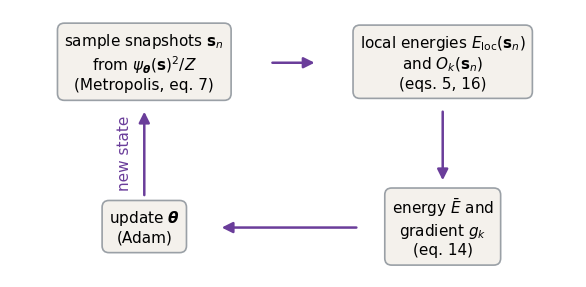

In [6]:
# --- figure (drawing code may be skipped): the loop of one iteration ---
def draw_loop(ax, dx=1.0, fontsize=11):
    # four boxes on a square cycle; dx is the horizontal distance between the box centres in data units
    boxes = {(0.0, 1.0): "sample snapshots $\\mathbf{s}_n$\nfrom $\\psi_{\\boldsymbol{\\theta}}(\\mathbf{s})^2/Z$\n(Metropolis, eq. 7)",
             (dx, 1.0): "local energies $E_{\\rm loc}(\\mathbf{s}_n)$\nand $O_k(\\mathbf{s}_n)$\n(eqs. 5, 16)",
             (dx, 0.0): "energy $\\bar E$ and\ngradient $g_k$\n(eq. 14)",
             (0.0, 0.0): "update $\\boldsymbol{\\theta}$\n(Adam)"}
    for (x, y), text in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize,
                bbox=dict(boxstyle="round,pad=0.45", fc="#F4F1EC", ec=COL["grey"], lw=1.2))
    arrow = dict(arrowstyle="-|>", color=COL["sampled"], lw=1.8, mutation_scale=16)
    ax.annotate("", xy=(0.58 * dx, 1.0), xytext=(0.42 * dx, 1.0), arrowprops=arrow)
    ax.annotate("", xy=(dx, 0.27), xytext=(dx, 0.72), arrowprops=arrow)
    ax.annotate("", xy=(0.25 * dx, 0.0), xytext=(0.72 * dx, 0.0), arrowprops=arrow)
    ax.annotate("", xy=(0.0, 0.72), xytext=(0.0, 0.18), arrowprops=arrow)
    ax.text(-0.04 * dx, 0.45, "new state", rotation=90, ha="right", va="center", color=COL["sampled"], fontsize=fontsize)
    ax.set_xlim(-0.45 * dx, 1.45 * dx); ax.set_ylim(-0.3, 1.32); ax.axis("off")
fig, ax = plt.subplots(figsize=(6.0, 3.0)); draw_loop(ax); fig.tight_layout(); save(fig, "fig_lab080_vmc_loop"); plt.show()
fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw_loop(ax, dx=1.2, fontsize=11); ax.set_xlim(-0.62, 1.82)
fig.subplots_adjust(left=0, right=1, top=1, bottom=0); save(fig, "fig_lab080_vmc_loop_a"); plt.close(fig)

The figure shows one iteration of variational Monte Carlo as a closed loop. The snapshots of an iteration come from the current parameters, they give the local energies and the derivatives $O_k$, these give the energy estimate and the gradient, Adam updates the parameters, and the next iteration samples from the new state. The figure writes $g_k$ for the gradient estimate $\partial_k\mathcal E$ of equation (14), and the code calls the standard deviation of the local energy `sigma_loc`. The functions `sample_step`, `estimate_step` and `make_update` implement the three operations of the loop, and `vmc` compiles one turn of the loop and runs it.

We train the network with $M=12$ at $g=J$ from the initial parameters of the best start of Section 4, small random numbers with standard deviation $0.05$. The loop uses 1000 Metropolis chains. Their configurations are carried from one iteration to the next and advance by two sweeps under the current parameters, so that the snapshots follow the changing state. The 1000 chains are independent of each other, and the error of $\bar{\mathcal E}$ in one iteration follows from equation (8) with one snapshot per chain. Adam uses the step size of Section 4, decreasing along a cosine from $0.03$ to $3\times10^{-4}$, over 1000 iterations. For the figure only, the code also evaluates the exact-sum energy of the current parameters in every iteration.

In [7]:
VMC_CHAINS, VMC_STEPS, VMC_SWEEPS = 1000, 1000, 2

# sample: every chain continues from its previous configuration for VMC_SWEEPS sweeps under the current parameters p
def sample_step(p, sigma, rng_key):
    history, acc = metropolis_sweeps(p, sigma, rng_key, VMC_SWEEPS)
    return history[-1], acc                                              # new snapshots, shape (VMC_CHAINS, N)

In [8]:
# estimate: local energies (5) of the snapshots, the energy estimate with its error (8), the variance of E_loc
# and the covariance gradient (14) with O_k from equation (16)
def estimate_step(p, sigma):
    e_zz, e_x = local_energy_parts(p, sigma, g_c)
    e_loc = e_zz + e_x                                                   # shape (n,)
    n = sigma.shape[0]
    grad = covariance_gradient(p, sigma, e_loc, jnp.full(n, 1.0 / n))    # same tree of shapes as p
    return grad, jnp.mean(e_loc), jnp.std(e_loc) / jnp.sqrt(n), jnp.var(e_loc)

In [9]:
# update: one Adam step with the sampled gradient; the step size decays along a cosine over all iterations
def make_update(lr, steps):
    opt = optax.adam(optax.cosine_decay_schedule(lr, steps, alpha=LR_END / LR))
    def update_step(p, opt_state, grad):
        updates, opt_state = opt.update(grad, opt_state)
        return optax.apply_updates(p, updates), opt_state
    return opt, update_step

variational Monte Carlo: 1000 chains, 1000 iterations, 2 sweeps per iteration, mean acceptance 0.38, 16.3 s
first iteration: estimate -11.761 +- 0.107 J, exact sum -11.827 J, variance of E_loc 11.52 J^2
last iteration:  estimate -14.9268 +- 0.0024 J, exact sum -14.9252 J, variance of E_loc 0.0060 J^2
final state by exact sums: relative energy error 5.4e-05, infidelity 1.0e-04
exact-sum training of Section 4, same start: relative energy error 1.9e-05 after 1000 iterations, 1.4e-05 after 2000
iterations in which the sampled estimate lies below E_0: 295 of 1000

core route (Sections 1 to 5): 38.0 s


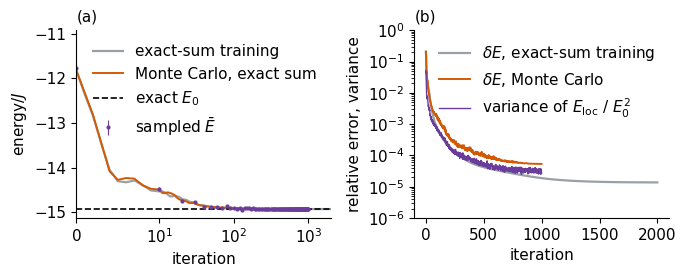

In [10]:
def vmc(p, n_chains, steps, lr, rng_key):
    # the loop of the figure; returns the final parameters and per iteration (E_bar, error, variance of E_loc, exact-sum energy, acceptance)
    opt, update_step = make_update(lr, steps)
    @jax.jit
    def iteration(p, opt_state, sigma, k):
        # one turn of the loop, compiled as a whole: sample, estimate, update
        sigma, acc = sample_step(p, sigma, k)                                 # sample from the current state
        grad, e_mean, e_err, e_var = estimate_step(p, sigma)                  # estimate energy and gradient
        record = jnp.stack([e_mean, e_err, e_var, energy(p, g_c), acc])      # exact-sum energy: diagnostic only
        p, opt_state = update_step(p, opt_state, grad)                        # update the parameters
        return p, opt_state, sigma, record
    opt_state = opt.init(p)
    keys = jax.random.split(rng_key, steps + 1)
    sigma = sample_sweeps(p, random_spins(n_chains), keys[-1], 50)[0][-1]     # 50 sweeps bring the chains to the initial state
    history = []
    for t in range(steps):
        p, opt_state, sigma, record = iteration(p, opt_state, sigma, keys[t])
        history.append(record)
    return p, np.asarray(jnp.stack(history))

t0 = time.perf_counter()
p_vmc, H_vmc = vmc(p_init, VMC_CHAINS, VMC_STEPS, LR, k_vmc)
time_vmc = time.perf_counter() - t0
E_bar, E_err, E_var, E_sums, acc_vmc = H_vmc.T
E0c = ex["E0"]
assert abs(E_sums[0] - r_main["E_hist"][b_main][0]) < 1e-10                   # the same starting state as in Section 4
psi_vmc = np.asarray(rbm_state(p_vmc))
E_vmc = float(psi_vmc @ (ex["H"] @ psi_vmc))
F_vmc = float((psi_vmc @ ex["psi0"]) ** 2)
rel_vmc = (E_vmc - E0c) / abs(E0c)
rel_exact_same = (r_main["E_hist"][b_main][VMC_STEPS - 1] - E0c) / abs(E0c)
below = int(np.sum(E_bar < E0c))
print(f"variational Monte Carlo: {VMC_CHAINS} chains, {VMC_STEPS} iterations, {VMC_SWEEPS} sweeps per iteration,"
      f" mean acceptance {acc_vmc.mean():.2f}, {time_vmc:.1f} s")
print(f"first iteration: estimate {E_bar[0]:.3f} +- {E_err[0]:.3f} J, exact sum {E_sums[0]:.3f} J, variance of E_loc {E_var[0]:.2f} J^2")
print(f"last iteration:  estimate {E_bar[-1]:.4f} +- {E_err[-1]:.4f} J, exact sum {E_sums[-1]:.4f} J, variance of E_loc {E_var[-1]:.4f} J^2")
print(f"final state by exact sums: relative energy error {rel_vmc:.1e}, infidelity {1 - F_vmc:.1e}")
print(f"exact-sum training of Section 4, same start: relative energy error {rel_exact_same:.1e} after {VMC_STEPS} iterations,"
      f" {r_main['rel_err'][b_main]:.1e} after {STEPS}")
print(f"iterations in which the sampled estimate lies below E_0: {below} of {VMC_STEPS}")

# --- figure (drawing code may be skipped) ---
it = np.arange(VMC_STEPS)
def draw_vmc_a(ax):
    ax.plot(np.arange(STEPS), r_main["E_hist"][b_main], color=COL["grey"], lw=1.6, label="exact-sum training")
    ax.errorbar(it[::10], E_bar[::10], yerr=E_err[::10], fmt=".", color=COL["sampled"], ms=4, lw=0.8, label=r"sampled $\bar E$")
    ax.plot(it, E_sums, color=COL["rbm"], lw=1.4, label="Monte Carlo, exact sum")
    ax.axhline(E0c, color=COL["exact"], ls="--", lw=1.2, label=r"exact $E_0$")
    ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, STEPS)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"energy$/J$"); ax.set_ylim(E0c - 0.2, E0c + 4.0)
    ax.legend(frameon=False, fontsize=11, loc="upper right")
def draw_vmc_b(ax):
    ax.semilogy(np.arange(STEPS), (r_main["E_hist"][b_main] - E0c) / abs(E0c), color=COL["grey"], lw=1.6, label=r"$\delta E$, exact-sum training")
    ax.semilogy(it, (E_sums - E0c) / abs(E0c), color=COL["rbm"], lw=1.4, label=r"$\delta E$, Monte Carlo")
    ax.semilogy(it, E_var / E0c ** 2, color=COL["sampled"], lw=1.0, label=r"variance of $E_{\rm loc}$ / $E_0^2$")
    ax.set_xlabel("iteration"); ax.set_ylabel("relative error, variance"); ax.set_ylim(1e-6, 1)
    ax.legend(frameon=False, fontsize=11, loc="upper right")
panels("fig_lab080_vmc_training", [draw_vmc_a, draw_vmc_b])
NUMBERS.update(VmcChains=str(VMC_CHAINS), VmcSteps=str(VMC_STEPS), VmcRelErr=sci(rel_vmc), VmcInfidelity=sci(1 - F_vmc),
               VmcLastEstimate=f"{E_bar[-1]:.4f}", VmcLastError=f"{E_err[-1]:.4f}", VmcBelow=str(below),
               VmcVarFirst=f"{E_var[0]:.1f}", VmcVarLast=sci(E_var[-1]), VmcRelErrExactSame=sci(rel_exact_same),
               VmcEnergy=f"{E_vmc:.6f}")
time_core = time.perf_counter() - started
print(f"\ncore route (Sections 1 to 5): {time_core:.1f} s")

Panel (a) shows the sampled energy $\bar{\mathcal E}$ with its error bars (every tenth iteration), the exact-sum energy of the same parameters (orange), the exact-sum training of Section 4 from the same start (grey) and $\mathcal E_0$ (dashed). The sampled estimates scatter around the orange line, and on the scale of this panel the Monte Carlo training follows the exact-sum training. The sampled estimate lies below $\mathcal E_0$ in 295 of the 1000 iterations, which the variational principle (9) allows, since it bounds the exact expectation value and a noisy estimate of it can fall below $\mathcal E_0$. Panel (b) shows the relative energy errors of both trainings, evaluated by exact sums, together with the variance of the local energy over the snapshots of each iteration. The variance falls from 11.5$\,J^2$ to $6.0\times10^{-3}\,J^2$ as the state approaches the ground state, the zero-variance property of Section 2 seen during training. After 1000 iterations the Monte Carlo training has $\delta\mathcal E=5.4\times10^{-5}$ and $1-F=1.0\times10^{-4}$, against $1.9\times10^{-5}$ for the exact-sum training after the same number of iterations.

Apart from the diagnostics, this training never used the list of all configurations. The cost per iteration is the number of chains times $N+1$ amplitudes for the local energies, each of the order of $NM$ operations, so the method reaches system sizes far beyond the exact sums, and with stochastic reconfiguration it trains networks of this type for long chains and two-dimensional lattices [1].

The core route ends here, and the last line of the output of the training cell gives its measured runtime.

## 6. At home. Number of hidden units

The number of hidden units $M$ sets the size of the network. We train networks with $M=1$, 2, 4, 8 and 24 hidden units by exact sums as in Section 4, with four starts each and the same budget of 2000 iterations, and add the network with $M=12$ of Section 4. For every start we record $\delta\mathcal E$, $1-F$ and the magnetisation per spin $\frac1N\sum_i\langle\hat\sigma^z_i\rangle$, which vanishes in the exact ground state because $\hat{\mathcal H}$ is unchanged when all spins are flipped. This section takes about half a minute.

   M   parameters   relative energy error of the four starts      infidelity of the four starts            |magnetisation per spin|
   1      25        2.8e-02   2.8e-02   2.8e-02   2.8e-02      6.5e-01   6.5e-01   6.5e-01   6.5e-01     0.780  0.780  0.780  0.780
   2      38        2.4e-02   2.2e-02   2.2e-02   2.4e-02      6.0e-01   5.9e-01   5.9e-01   6.0e-01     0.734  0.737  0.737  0.734
   4      64        8.7e-03   8.7e-03   8.7e-03   8.7e-03      3.1e-02   3.1e-02   3.1e-02   3.1e-02     0.000  0.000  0.000  0.000
   8     116        5.3e-05   5.1e-05   4.9e-05   5.5e-05      1.2e-04   1.1e-04   1.1e-04   1.1e-04     0.000  0.000  0.000  0.000
  12     168        2.2e-05   2.2e-05   1.5e-05   1.4e-05      4.1e-05   4.1e-05   2.6e-05   2.6e-05     0.000  0.000  0.000  0.000
  24     324        9.4e-06   8.8e-06   8.9e-06   1.1e-05      1.5e-05   1.4e-05   1.4e-05   1.8e-05     0.000  0.000  0.000  0.000
scan over the number of hidden units (M = 1, 2, 4, 8, 24 trained here): 37.9

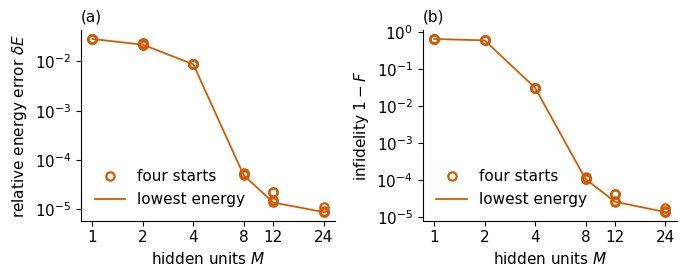

In [11]:
t_home = time.perf_counter()
WORD = {1: "One", 2: "Two", 4: "Four", 8: "Eight", 12: "Twelve", 16: "Sixteen", 24: "TwentyFour"}
M_LIST = (1, 2, 4, 8, 12, 24)
mag_z = lambda psi: float(np.mean(SIGMA, axis=1) @ psi ** 2)           # (1/N) sum_i <sigma^z_i> from the probabilities
print("   M   parameters   relative energy error of the four starts      infidelity of the four starts            |magnetisation per spin|")
for M in M_LIST:
    r = RUNS[g_c, M, True] if (g_c, M, True) in RUNS else run(g_c, M)
    print(f"  {M:2d}   {r['n_params']:5d}       " + "  ".join(f"{x:8.1e}" for x in r["rel_err"])
          + "     " + "  ".join(f"{x:8.1e}" for x in 1 - r["F"]) + "     " + "  ".join(f"{abs(mag_z(x)):5.3f}" for x in r["psi"]))
    NUMBERS["EnergyHidden" + WORD[M]] = f"{r['E'][r['best']]:.6f}"
    NUMBERS["RelErrHidden" + WORD[M]] = sci(r["rel_err"][r["best"]])
    NUMBERS["InfidelityHidden" + WORD[M]] = sci(1 - r["F"][r["best"]])
    NUMBERS["ParamsHidden" + WORD[M]] = str(r["n_params"])
    NUMBERS["MagHidden" + WORD[M]] = f"{max(abs(mag_z(x)) for x in r['psi']):.2f}"
time_hidden = time.perf_counter() - t_home
print(f"scan over the number of hidden units (M = 1, 2, 4, 8, 24 trained here): {time_hidden:.1f} s")

# --- figure (drawing code may be skipped) ---
def draw_hidden(quantity, label):
    def draw(ax):
        best = []
        for M in M_LIST:
            r = RUNS[g_c, M, True]
            y = r["rel_err"] if quantity == "E" else 1 - r["F"]
            ax.loglog(np.full(STARTS, M), y, "o", color=COL["rbm"], ms=6, mfc="none", mew=1.6,
                      label="four starts" if M == M_LIST[0] else None)
            best.append(y[r["best"]])
        ax.loglog(M_LIST, best, color=COL["rbm"], lw=1.3, label="lowest energy")
        ax.set_xticks(M_LIST); ax.set_xticklabels([str(M) for M in M_LIST]); ax.minorticks_off()
        ax.set_xlabel("hidden units $M$"); ax.set_ylabel(label); ax.legend(frameon=False, loc="lower left")
    return draw
panels("fig_lab080_hidden_scan", [draw_hidden("E", r"relative energy error $\delta E$"), draw_hidden("F", "infidelity $1-F$")])

The figure shows the relative energy error in panel (a) and the infidelity in panel (b) against the number of hidden units on logarithmic axes. The circles are the four starts and the line joins the starts of lowest energy, whose values the table lists.

| $M$ | stored numbers $N+M+NM$ | $\delta\mathcal E$ | $1-F$ | magnetised starts |
|---|---|---|---|---|
| 1 | 25 | $2.8\times10^{-2}$ | $6.5\times10^{-1}$ | 4 |
| 2 | 38 | $2.2\times10^{-2}$ | $5.9\times10^{-1}$ | 4 |
| 4 | 64 | $8.7\times10^{-3}$ | $3.1\times10^{-2}$ | 0 |
| 8 | 116 | $4.9\times10^{-5}$ | $1.1\times10^{-4}$ | 0 |
| 12 | 168 | $1.4\times10^{-5}$ | $2.6\times10^{-5}$ | 0 |
| 24 | 324 | $8.8\times10^{-6}$ | $1.4\times10^{-5}$ | 0 |

With one and two hidden units all starts end in a state magnetised along $z$, with a magnetisation per spin of magnitude up to $0.78$, and their fidelity with the unmagnetised ground state stays below one half. From four hidden units on all starts are unmagnetised. The energy error falls by more than three orders of magnitude between $M=1$ and $M=24$, most of it between $M=4$ and $M=8$, and each further hidden unit gains little. These are four starts per size with a fixed budget of 2000 iterations, so the values for large $M$ are upper bounds on the error that networks of this size can reach.

## 7. At home. Ordered phase and the spin-flip symmetry

The Hamiltonian (1) is unchanged when all spins are flipped, and its exact ground state has the same amplitude for $\boldsymbol\sigma$ and $-\boldsymbol\sigma$. In the ordered phase at $g=0.5J$ the first excited state, which changes sign under the flip, lies very close to the ground state. The normalised sum and difference of the two states are magnetised up or down, with an energy half the gap above $\mathcal E_0$ and a fidelity of one half with the ground state. An optimiser that minimises the energy barely distinguishes these states from the ground state.

We train the network with $M=12$ at $g=0.5J$ twice, by exact sums. The first run keeps all parameters. The second run fixes the biases at zero, $a_i=0$ and $b_j=0$, and trains only the weights. Equation (3) then contains only $2\cosh\big(\sum_iw_{ij}\sigma_i\big)$, an even function of the spins, so $\psi(-\boldsymbol\sigma)=\psi(\boldsymbol\sigma)$ holds for any weights and the magnetised states are excluded by construction. The exact ground state and the gap at $g=0.5J$ come from the diagonalisation of the Hamiltonian matrix. This section takes about twenty seconds.

g = 0.5 J, M = 12: exact E_0 = -11.892045 J, gap to the first excited state 3.66e-04 J
  network          start   relative energy error   fidelity F   magnetisation per spin   max |C - C_exact|
  with biases        0         6.26e-05           0.50153         +0.9448              1.8e-03
  with biases        1         6.54e-05           0.50197         -0.9450              2.2e-03
  with biases        2         6.94e-05           0.50120         +0.9449              1.9e-03
  with biases        3         4.88e-05           0.50104         -0.9447              1.3e-03
  biases set to 0    0         8.76e-05           0.99969         +0.0000              2.7e-03
  biases set to 0    1         6.06e-05           0.99980         -0.0000              1.8e-03
  biases set to 0    2         5.63e-05           0.99981         +0.0000              1.7e-03
  biases set to 0    3         5.57e-05           0.99984         -0.0000              1.7e-03
energy of the first excited state above E_0, r

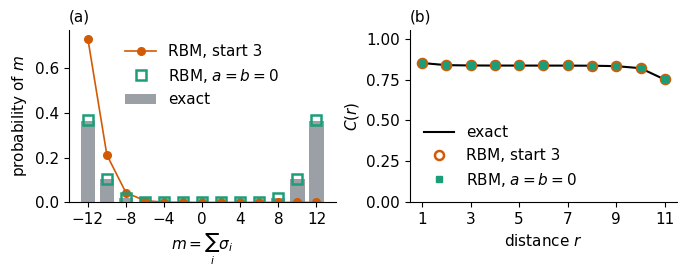

In [12]:
g_ord = 0.5                                                             # ordered phase, g = 0.5 J
EXACT[g_ord] = exact_ground_state(g_ord)
ex_o = EXACT[g_ord]
def adam_run_even(p0, g, psi0):
    # as adam_run, but only the weights W (w_ij) are trained; a = 0 and b = 0 stay fixed, so psi(-sigma) = psi(sigma)
    W0 = p0["W"]
    full = lambda W: dict(a=jnp.zeros_like(p0["a"]), b=jnp.zeros_like(p0["b"]), W=W)
    def step(carry, _):
        W, opt_state = carry
        E, grad = jax.value_and_grad(lambda W: energy(full(W), g))(W)
        F = (rbm_state(full(W)) @ psi0) ** 2
        updates, opt_state = optimiser.update(grad, opt_state)
        return (optax.apply_updates(W, updates), opt_state), (E, F)
    (W, _), (E_hist, F_hist) = jax.lax.scan(step, (W0, optimiser.init(W0)), None, length=STEPS)
    return full(W), E_hist, F_hist
train_even = jax.jit(jax.vmap(adam_run_even, in_axes=(0, None, None)))   # all starts at once

t_ord = time.perf_counter()
r_full, r_even = run(g_ord, M_MAIN, True), run(g_ord, M_MAIN, False)
print(f"g = {g_ord} J, M = {M_MAIN}: exact E_0 = {ex_o['E0']:.6f} J, gap to the first excited state {ex_o['gap']:.2e} J")
print("  network          start   relative energy error   fidelity F   magnetisation per spin   max |C - C_exact|")
for name, r in (("with biases", r_full), ("biases set to 0", r_even)):
    for k in range(STARTS):
        print(f"  {name:15s}    {k}        {r['rel_err'][k]:9.2e}          {r['F'][k]:8.5f}        {mag_z(r['psi'][k]):+8.4f}"
              f"             {np.max(np.abs(r['C'][k] - ex_o['C'])):8.1e}")
k_low = int(np.argmin(r_full["F"]))                                    # the start with biases that has the lowest fidelity
k_even = r_even["best"]
print(f"energy of the first excited state above E_0, relative to |E_0|: {ex_o['gap'] / abs(ex_o['E0']):.2e}")
time_ordered = time.perf_counter() - t_ord

# --- figure (drawing code may be skipped) ---
def prob_of_m(psi):
    return np.array([np.sum(psi[MAG == m] ** 2) for m in np.arange(-N, N + 1, 2)])
def draw_ord_a(ax):
    m_axis = np.arange(-N, N + 1, 2)
    ax.bar(m_axis, prob_of_m(ex_o["psi0"]), width=1.5, color=COL["grey"], label="exact")
    ax.plot(m_axis, prob_of_m(r_full["psi"][k_low]), "o-", color=COL["rbm"], ms=5.5, lw=1.2, label=f"RBM, start {k_low}")
    ax.plot(m_axis, prob_of_m(r_even["psi"][k_even]), "s", color=COL["even"], ms=6.5, mfc="none", mew=1.8, label="RBM, $a=b=0$")
    ax.set_xlabel(r"$m=\sum_i \sigma_i$"); ax.set_ylabel("probability of $m$"); ax.set_xticks(m_axis[::2])
    ax.legend(frameon=False, loc="upper center", fontsize=11)
def draw_ord_b(ax):
    ax.plot(range(1, N), ex_o["C"], color=COL["exact"], lw=1.5, label="exact")
    ax.plot(range(1, N), r_full["C"][k_low], "o", color=COL["rbm"], ms=6.5, mfc="none", mew=1.8, label=f"RBM, start {k_low}")
    ax.plot(range(1, N), r_even["C"][k_even], "s", color=COL["even"], ms=4, label="RBM, $a=b=0$")
    ax.set_xticks(range(1, N, 2)); ax.set_xlabel("distance $r$"); ax.set_ylabel("$C(r)$"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, loc="lower left")
panels("fig_lab080_ordered_phase", [draw_ord_a, draw_ord_b])
NUMBERS.update(EZeroOrdered=f"{ex_o['E0']:.4f}", GapOrdered=sci(ex_o["gap"]), GapOrderedRel=sci(ex_o["gap"] / abs(ex_o["E0"])),
               OrderedReachedFull=str(int(np.sum(r_full["F"] > 0.99))), OrderedReachedEven=str(int(np.sum(r_even["F"] > 0.99))),
               OrderedFidMin=f"{r_full['F'].min():.3f}", OrderedFidMax=f"{r_full['F'].max():.3f}",
               OrderedRelErrFullMin=sci(r_full["rel_err"].min()), OrderedRelErrFullMax=sci(r_full["rel_err"].max()),
               OrderedMagLow=f"{abs(mag_z(r_full['psi'][k_low])):.2f}",
               OrderedCorrErrLow=sci(np.max(np.abs(r_full["C"][k_low] - ex_o["C"]))),
               OrderedInfidelityEven=sci(1 - r_even["F"][k_even]), OrderedRelErrEven=sci(r_even["rel_err"][k_even]),
               OrderedInfidelityEvenWorst=sci(1 - r_even["F"].min()), OrderedParamsEven=str(r_even["n_params"]))

The gap at $g=0.5J$ is $3.7\times10^{-4}\,J$, a fraction $3.1\times10^{-5}$ of $|\mathcal E_0|$. With biases, all four starts end in a magnetised state, with a magnetisation per spin of magnitude $0.94$ and fidelities between $0.501$ and $0.502$. Their relative energy errors, between $4.9\times10^{-5}$ and $6.9\times10^{-5}$, exceed the relative gap, so the error left by the training is larger than the energy that separates the magnetised states from the ground state. Panel (a) shows the probability of the total spin $m=\sum_i\sigma_i$. The exact ground state (grey bars) has two equal peaks at $m=\pm12$, and the magnetised start (orange) has kept one of them. Panel (b) shows that its correlation function still follows the exact curve within $1.3\times10^{-3}$, because $\sigma_0\sigma_r$ takes the same value in a configuration and in its flipped partner. A small energy error and a correct correlation function are therefore compatible with a fidelity of one half. Without biases (teal, labelled $a=b=0$ in the legend) all four starts reach fidelities above $0.999$, with infidelities of at most $3.1\times10^{-4}$, and reproduce both peaks. The symmetry built into the network removes the magnetised minima and reduces the number of parameters from 168 to 144.

## 8. At home. Longer Monte Carlo training

The Monte Carlo training of Section 5 used 1000 chains and 1000 iterations. Here we repeat it from the same initial parameters with 2000 chains and 3000 iterations, with an initial step size of $0.02$ decaying along a cosine to $2\times10^{-4}$. More chains reduce the noise of the gradient, and more iterations with a smaller step let the parameters settle closer to the minimum. The run uses one seed and takes about a minute.

longer run: 2000 chains, 3000 iterations, 115.9 s
  relative energy error 1.6e-05, infidelity 3.3e-05, last variance of E_loc 2.1e-03 J^2
Section 5 run: relative energy error 5.4e-05; exact-sum training: 1.4e-05 after 2000 iterations
at-home sections 6 to 8: 177.2 s


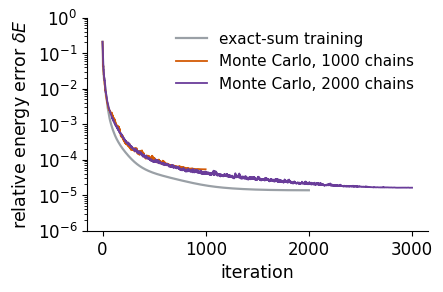

In [13]:
LONG_CHAINS, LONG_STEPS, LONG_LR = 2000, 3000, 0.02
t0 = time.perf_counter()
p_long, H_long = vmc(p_init, LONG_CHAINS, LONG_STEPS, LONG_LR, k_long)
time_long = time.perf_counter() - t0
psi_long = np.asarray(rbm_state(p_long))
E_long = float(psi_long @ (ex["H"] @ psi_long))
rel_long, F_long = (E_long - E0c) / abs(E0c), float((psi_long @ ex["psi0"]) ** 2)
print(f"longer run: {LONG_CHAINS} chains, {LONG_STEPS} iterations, {time_long:.1f} s")
print(f"  relative energy error {rel_long:.1e}, infidelity {1 - F_long:.1e}, last variance of E_loc {H_long[-1, 2]:.1e} J^2")
print(f"Section 5 run: relative energy error {rel_vmc:.1e}; exact-sum training: {r_main['rel_err'][b_main]:.1e} after {STEPS} iterations")

# --- figure (drawing code may be skipped) ---
def draw_long(ax):
    ax.semilogy(np.arange(STEPS), (r_main["E_hist"][b_main] - E0c) / abs(E0c), color=COL["grey"], lw=1.6, label="exact-sum training")
    ax.semilogy(np.arange(VMC_STEPS), (E_sums - E0c) / abs(E0c), color=COL["rbm"], lw=1.3, label=f"Monte Carlo, {VMC_CHAINS} chains")
    ax.semilogy(np.arange(LONG_STEPS), (H_long[:, 3] - E0c) / abs(E0c), color=COL["sampled"], lw=1.3, label=f"Monte Carlo, {LONG_CHAINS} chains")
    ax.set_xlabel("iteration"); ax.set_ylabel(r"relative energy error $\delta E$"); ax.set_ylim(1e-6, 1); ax.legend(frameon=False, fontsize=11)
one_panel("fig_lab080_vmc_long", draw_long)
time_home = time.perf_counter() - t_home
print(f"at-home sections 6 to 8: {time_home:.1f} s")
NUMBERS.update(VmcLongChains=str(LONG_CHAINS), VmcLongSteps=str(LONG_STEPS), VmcLongRelErr=sci(rel_long), VmcLongInfidelity=sci(1 - F_long))

The figure shows the relative energy error, evaluated by exact sums, of the two Monte Carlo runs and of the exact-sum training against the iteration. The longer run reaches $\delta\mathcal E=1.6\times10^{-5}$ and $1-F=3.3\times10^{-5}$.

## 9. Summary

The ground state of a Hamiltonian is found without data, by lowering the energy of the network. The energy is bounded from below by the ground-state energy, so its minimum over the parameters is the closest approach to the ground state that the network allows. For twelve spins the energy can be minimised as an exact sum, and the network with twelve hidden units reached a relative energy error of $1.4\times10^{-5}$ from small random parameters. Lab 080 samples this network.

The gradient of the energy is twice the covariance of the local energy and the logarithmic derivative of the amplitude, an average minus an average like the Boltzmann learning rule, with both averages taken over snapshots generated by the network itself. At an eigenstate every snapshot has the same local energy, so every covariance vanishes and the training stops, which two spins showed with one parameter and the falling variance of the local energy showed during training. Variational Monte Carlo with this gradient trained the network with twelve hidden units from the same start to a relative energy error of $5.4\times10^{-5}$ for the chain of twelve spins at the critical field, and it used the list of all configurations only for diagnostics. With one or two hidden units the training ended in magnetised states, from four hidden units on it found unmagnetised states, and in the ordered phase a network without biases excluded the magnetised states by construction.

Lab 088 evolves the same kind of network, with complex parameters, in imaginary and real time.

## 10. Exercises

1. Derive equation (15) for the two-spin table $(1,e^\theta,e^\theta,1)$ from the covariance (13), and show that the gradient vanishes at $\zeta=(\sqrt5-1)/2$.
2. Show that the estimate (14) is zero for every set of snapshots when all snapshots have the same local energy, and explain why the Monte Carlo training of Section 5 stops at an eigenstate.
3. Derive the derivatives (16) from the amplitude (3), using $d\ln(2\cosh u)/du=\tanh u$.
4. At home, reduce the number of chains in Section 5 from 1000 to 100. Report the final relative energy error, evaluated by exact sums, and the scatter of $\bar{\mathcal E}$ next to the recorded run.

## References

[1] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:10.1126/science.aag2302.

[2] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:10.1016/0003-4916(70)90270-8.

[3] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), https://arxiv.org/abs/1412.6980.

[4] DeepMind, Optax, gradient processing and optimisation for JAX, https://github.com/google-deepmind/optax.

[5] W. L. McMillan, Ground state of liquid He$^4$, Phys. Rev. **138**, A442 (1965), doi:10.1103/PhysRev.138.A442.

[6] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, Equation of state calculations by fast computing machines, J. Chem. Phys. **21**, 1087 (1953), doi:10.1063/1.1699114.

[7] P. Virtanen *et al.*, SciPy 1.0: fundamental algorithms for scientific computing in Python, Nat. Methods **17**, 261 (2020), doi:10.1038/s41592-019-0686-2.

[8] S. Sorella, Green function Monte Carlo with stochastic reconfiguration, Phys. Rev. Lett. **80**, 4558 (1998), doi:10.1103/PhysRevLett.80.4558.

[9] G. Torlai, G. Mazzola, J. Carrasquilla, M. Troyer, R. Melko and G. Carleo, Neural-network quantum state tomography, Nat. Phys. **14**, 447 (2018), doi:10.1038/s41567-018-0048-5.

The last cell writes every number quoted in the text to the results file and to the macro file, and prints the measured runtimes.

In [14]:
# --- bookkeeping (may be skipped): every recorded number to JSON and to the LaTeX macro file ---
def run_record(r):
    return dict(parameters=r["n_params"], energy=r["E"].tolist(), relative_energy_error=r["rel_err"].tolist(), fidelity=r["F"].tolist(),
                correlations_s0_sr=r["C"].tolist(), best_start=r["best"],
                energy_decrease_last_100_steps_over_E0=r["drift"].tolist(), seconds=r["seconds"])
summary = dict(
    experiment="Training of the RBM wave function with real parameters for the open transverse-field Ising chain (N = 12): exact-sum "
               "training (reference, writes data/rbm_tfim_N12_M12_params.npz read by Lab 080 of Lecture 15), variational Monte Carlo "
               "with the covariance gradient and Adam (Optax); JAX float64 on CPU",
    model=dict(N=N, J=J, fields=[float(x) for x in EXACT], hamiltonian="-J sum Z_i Z_{i+1} - g sum X_i, open chain"),
    checks=dict(energy_all_parameters_zero=E_zero, two_spins_E0=E0_two, two_spins_r=float(r_star),
                covariance_gradient_vs_autodiff=grad_check),
    exact={str(g): dict(E0=e["E0"], gap=e["gap"], correlations_s0_sr=e["C"].tolist()) for g, e in EXACT.items()},
    optimisation=dict(optimiser="optax.adam", steps=STEPS, step_size_start=LR, step_size_end=LR_END, schedule="cosine decay",
                      starts=STARTS, initial_width=0.05),
    runs={f"g={g} M={M} {'with biases' if b else 'a=b=0'}": run_record(r) for (g, M, b), r in RUNS.items()},
    two_spin_descent={k_: dict(final_r=float(np.exp(d[-1, 0])), final_energy=float(d[-1, 1])) for k_, d in DESCENT.items()},
    variational_monte_carlo=dict(g=g_c, M=M_MAIN, chains=VMC_CHAINS, iterations=VMC_STEPS, sweeps_per_iteration=VMC_SWEEPS, runs=1,
                                 relative_energy_error_exact_sum=rel_vmc, fidelity=F_vmc, energy_exact_sum=E_vmc,
                                 last_estimate=float(E_bar[-1]), last_standard_error=float(E_err[-1]),
                                 local_energy_variance_first_last=[float(E_var[0]), float(E_var[-1])], estimates_below_E0=below,
                                 exact_sum_training_same_iterations=float(rel_exact_same), seconds=time_vmc),
    variational_monte_carlo_long=dict(chains=LONG_CHAINS, iterations=LONG_STEPS, step_size_start=LONG_LR, runs=1,
                                      relative_energy_error_exact_sum=rel_long, fidelity=F_long, seconds=time_long),
    runtime_seconds=dict(core_sections_1_5=time_core, at_home_sections_6_8=time_home, vmc=time_vmc, total=time.perf_counter() - started))
NUMBERS.update(RuntimeTrainingCore=f"{time_core:.0f}", RuntimeTrainingHome=f"{time_home:.0f}")
(RES / "lab080b_results.json").write_text(json.dumps(summary, indent=2))
with open(FIG / "nb_numbers_lab080b.tex", "w") as f:
    f.write("% numbers of Lab 080b (Lecture 16, training of the N = 12 transverse-field Ising chain); prefix \\labeightyNQS shared with Lab 080, "
            "whose file nb_numbers_lab080.tex defines the other names\n")
    for k_, v_ in NUMBERS.items():
        f.write(f"\\newcommand{{\\labeightyNQS{k_}}}{{{v_.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime: Sections 1-5 {time_core:.1f} s, Sections 6-8 {time_home:.1f} s, total {summary['runtime_seconds']['total']:.1f} s")
print("written: classroom_results/lab080b_results.json, figures/nb_numbers_lab080b.tex, data/rbm_tfim_N12_M12_params.npz and the figures")

numbers: {'Steps': '2000', 'Starts': '4', 'RelErrMain': '1.4\\times10^{-5}', 'InfidelityMain': '2.6\\times10^{-5}', 'RelErrMainWorst': '2.2\\times10^{-5}', 'InfidelityMainWorst': '4.1\\times10^{-5}', 'RelErrMainBest': '1.4\\times10^{-5}', 'InfidelityMainBest': '2.6\\times10^{-5}', 'CorrErrMain': '5.0\\times10^{-4}', 'AmpRatioMin': '0.966', 'AmpRatioMax': '1.029', 'VmcChains': '1000', 'VmcSteps': '1000', 'VmcRelErr': '5.4\\times10^{-5}', 'VmcInfidelity': '1.0\\times10^{-4}', 'VmcLastEstimate': '-14.9268', 'VmcLastError': '0.0024', 'VmcBelow': '295', 'VmcVarFirst': '11.5', 'VmcVarLast': '6.0\\times10^{-3}', 'VmcRelErrExactSame': '1.9\\times10^{-5}', 'VmcEnergy': '-14.925172', 'EnergyHiddenOne': '-14.501742', 'RelErrHiddenOne': '2.8\\times10^{-2}', 'InfidelityHiddenOne': '6.5\\times10^{-1}', 'ParamsHiddenOne': '25', 'MagHiddenOne': '0.78', 'EnergyHiddenTwo': '-14.601006', 'RelErrHiddenTwo': '2.2\\times10^{-2}', 'InfidelityHiddenTwo': '5.9\\times10^{-1}', 'ParamsHiddenTwo': '38', 'MagHidde